<a href="https://colab.research.google.com/github/Ahmed-Mazhar1/Computer-Vision/blob/main/Lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

A = cv2.cvtColor(cv2.imread('/content/f1.png'), cv2.COLOR_BGR2GRAY).astype(np.float32)
B = cv2.cvtColor(cv2.imread('/content/f2.png'), cv2.COLOR_BGR2GRAY).astype(np.float32)

# Resize B if the dimensions are different
if A.shape != B.shape:
    B = cv2.resize(
        B,
        (A.shape[1], A.shape[0]),
        interpolation=cv2.INTER_LINEAR
    )
    # interpolation: When resizing image B, estimate new pixel values by taking weighted averages of nearby pixels to produce a smooth result.

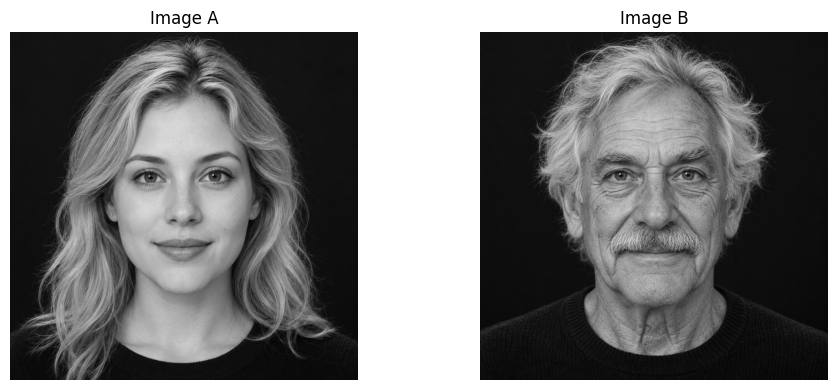

In [3]:
# Display both images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Image A")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(B, cmap="gray", vmin=0, vmax=255)
plt.title("Image B")
plt.axis("off")

plt.tight_layout()
plt.show()

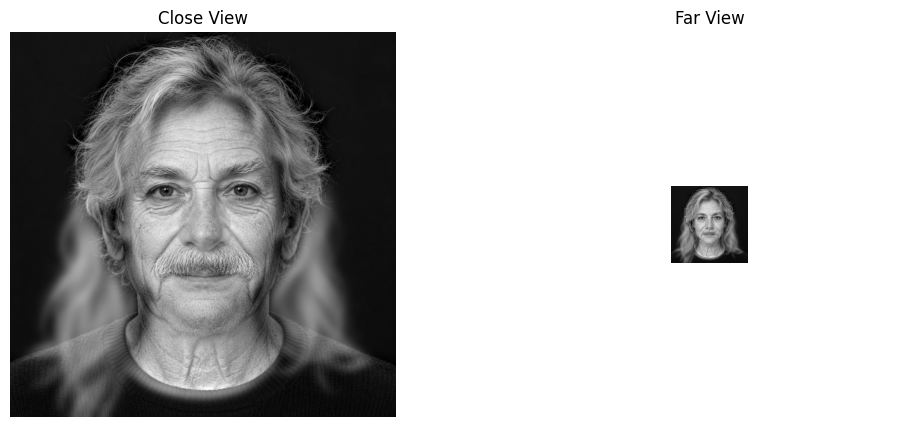

In [4]:
sigma_low = 12
sigma_high = 15

low = cv2.GaussianBlur(A, (0, 0), sigma_low)

blurred_B = cv2.GaussianBlur(B, (0, 0), sigma_high)
high = B - blurred_B

hybrid = np.clip(low + high, 0, 255).astype(np.uint8)

hybrid_uint8 = hybrid.astype(np.uint8)

thumbnail = cv2.resize(
    hybrid_uint8,
    None,
    fx=0.2,
    fy=0.2,
    interpolation=cv2.INTER_AREA
)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(hybrid, cmap='gray', vmin=0, vmax=255)
ax[0].set_title("Close View")
ax[0].axis("off")

ax[1].imshow(
    hybrid,
    cmap='gray',
    vmin=0,
    vmax=255,
    extent=(0, 1, 0, 1)
)
ax[1].set_xlim(-2, 3)
ax[1].set_ylim(-2, 3)
ax[1].set_title("Far View")
ax[1].axis("off")

plt.show()

In [5]:
shape = cv2.cvtColor(cv2.imread('/content/shape.jpg'), cv2.COLOR_BGR2GRAY)
coins = cv2.cvtColor(cv2.imread('/content/coins.jpg'), cv2.COLOR_BGR2GRAY)
r1 = cv2.cvtColor(cv2.imread('/content/road1.jpg'), cv2.COLOR_BGR2GRAY)
r2 = cv2.cvtColor(cv2.imread('/content/road2.jpg'), cv2.COLOR_BGR2GRAY)
r3 = cv2.cvtColor(cv2.imread('/content/road3.jpg'), cv2.COLOR_BGR2GRAY)

def show(img, title=''):
    # OpenCV is BGR; matplotlib expects RGB
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(img)
    else:
        plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title(title); plt.axis('off'); plt.show()

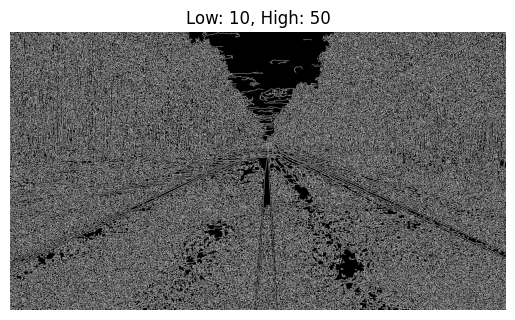

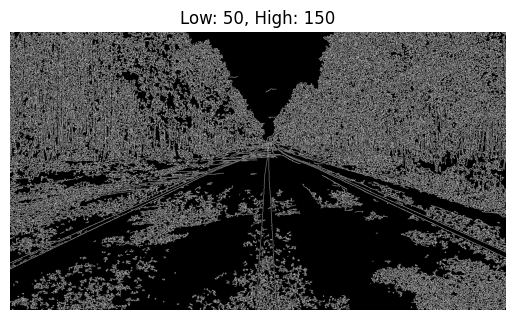

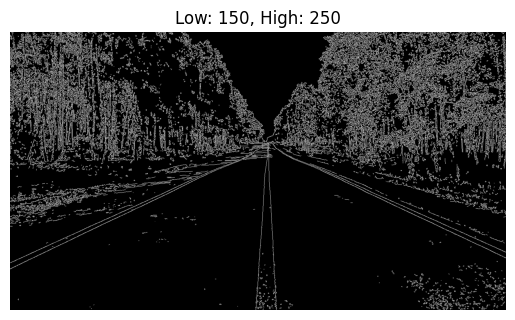

In [ ]:
# Task 1
threshold_pairs = [(10, 50), (50, 150), (150, 250)]

for i, (low, high) in enumerate(threshold_pairs):
      edges = cv2.Canny(r1, low, high)
      show(edges, f"Low: {low}, High: {high}")


(np.float64(-0.5), np.float64(1533.5), np.float64(859.5), np.float64(-0.5))

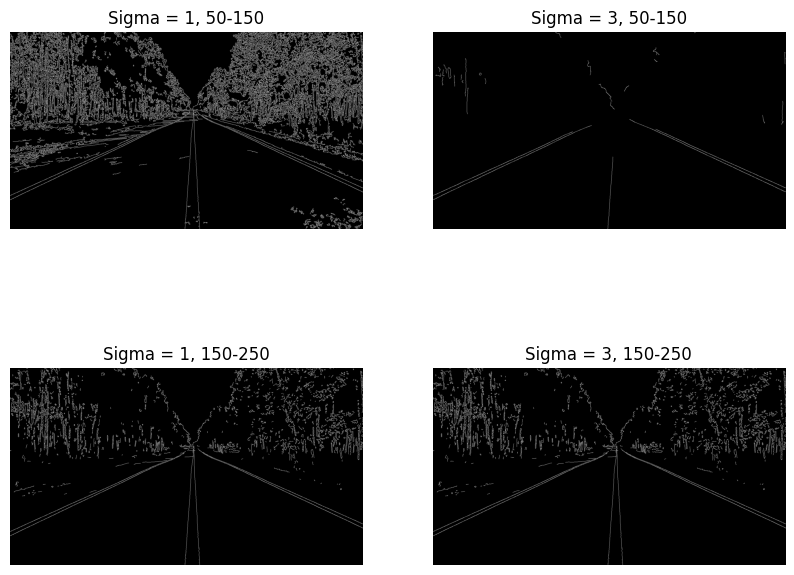

In [ ]:
blur1 = cv2.GaussianBlur(r1, (0, 0), sigmaX=1)
blur3 = cv2.GaussianBlur(r1, (0, 0), sigmaX=3)

edges1 = cv2.Canny(blur1, 50, 150)
edges3 = cv2.Canny(blur3, 50, 150)

edges11 = cv2.Canny(blur1, 150, 250)
edges33 = cv2.Canny(blur3, 150, 250)

plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(edges1, cmap='gray')
plt.title("Sigma = 1, 50-150")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(edges3, cmap='gray')
plt.title("Sigma = 3, 50-150")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(edges11, cmap='gray')
plt.title("Sigma = 1, 150-250")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(edges11, cmap='gray')
plt.title("Sigma = 3, 150-250")
plt.axis("off")

Lower Canny thresholds detect more edges, including weak lane markings, trees, and noise. Higher thresholds suppress weak edges but may also remove faint lane markings. Gaussian blur reduces small image details before edge detection, with larger sigma values producing stronger smoothing. The best combination is the one that preserves continuous lane markings while minimizing unwanted tree edges; this must be determined by comparing the results on road1.jpg.

In [ ]:
#Task 2
edges = cv2.Canny(shape, 50, 150)

lines = cv2.HoughLines(
    edges,
    rho=1,
    theta=np.pi / 180,
    threshold=80
)

if lines is not None:
    for line in lines:
        rho, theta = line[0]
        print(f"rho = {rho:.2f}, theta = {np.degrees(theta):.2f} degrees")
else:
    print("No lines detected")

rho = 1017.00, theta = 90.00 degrees
rho = -427.00, theta = 150.00 degrees
rho = 991.00, theta = 90.00 degrees
rho = 637.00, theta = 30.00 degrees
rho = -401.00, theta = 150.00 degrees
rho = 611.00, theta = 30.00 degrees
rho = 629.00, theta = 29.00 degrees
rho = 606.00, theta = 29.00 degrees
rho = -445.00, theta = 151.00 degrees
rho = 626.00, theta = 29.00 degrees
rho = 647.00, theta = 31.00 degrees
rho = -387.00, theta = 149.00 degrees
rho = -385.00, theta = 149.00 degrees
rho = -382.00, theta = 149.00 degrees
rho = -420.00, theta = 151.00 degrees
rho = -417.00, theta = 151.00 degrees
rho = 614.00, theta = 28.00 degrees
rho = 609.00, theta = 29.00 degrees
rho = 632.00, theta = 29.00 degrees
rho = 644.00, theta = 31.00 degrees
rho = -379.00, theta = 149.00 degrees
rho = -443.00, theta = 151.00 degrees
rho = -424.00, theta = 151.00 degrees
rho = 634.00, theta = 29.00 degrees
rho = 601.00, theta = 29.00 degrees
rho = 615.00, theta = 31.00 degrees
rho = 642.00, theta = 31.00 degrees
rho =

rho=x cos(theta)+y sin(theta)

rho = 1017 , theta = 90

1017= 0x + y

y= 1017

x= 500 , x=800

rho=500(0)+1017(1)=1017

rho=800(0)+1017(1)=1017

Both points satisfy the detected Hough line equation.


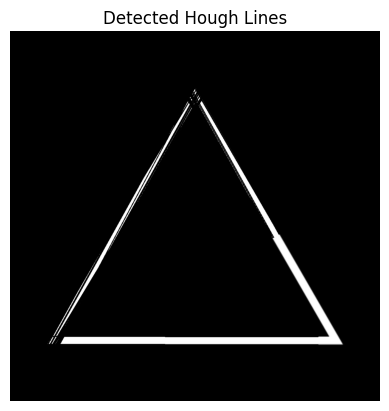

In [ ]:
output = shape.copy()

if lines is not None:
    for line in lines:
        rho, theta = line[0]

        a = np.cos(theta)
        b = np.sin(theta)

        x0 = a * rho
        y0 = b * rho

        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * a)

        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * a)

        cv2.line(output, (x1, y1), (x2, y2), (0, 0, 255), 2)

show(cv2.cvtColor(output, cv2.COLOR_BGR2RGB),
     "Detected Hough Lines")

In [ ]:
#Task 3
blur = cv2.GaussianBlur(coins, (9, 9), 2)

circles = cv2.HoughCircles(
    blur,
    cv2.HOUGH_GRADIENT,
    dp=1,
    minDist=40, #threshold of distnace between centers of any 2 circles detected
    param1=120, #High threshold, and the low threshold = 0.5*120
    param2=35,  #voting threshold
    minRadius=15,
    maxRadius=60
)

Number of coins: 58


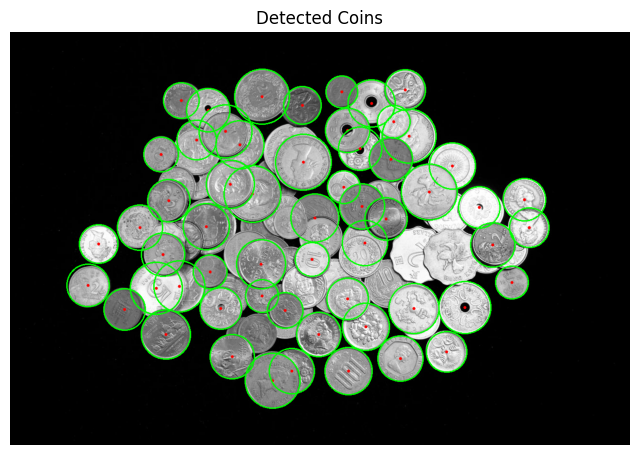

In [ ]:
img = cv2.cvtColor(coins, cv2.COLOR_GRAY2BGR)
output = img.copy()

if circles is not None:

    circles = np.round(circles[0]).astype(int)

    for x, y, r in circles:

        # Draw circle boundary
        cv2.circle(output, (x, y), r, (0, 255, 0), 2)

        # Draw circle center
        cv2.circle(output, (x, y), 3, (0, 0, 255), -1)

    print("Number of coins:", len(circles))

else:
    print("No circles detected")

# Display result
plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Detected Coins")
plt.axis("off")
plt.show()

The param2 parameter mainly controls false positives. Lowering param2 makes circle detection less strict, which may detect more circles, including incorrect ones.

The minDist parameter mainly controls duplicate detections. Lowering minDist allows detected circle centers to be closer together, which may cause multiple detections of the same coin.

Therefore, param2 is important for reducing false positives, while minDist is important for preventing duplicate detections.

In [6]:
def detect_lanes(img, show_mask=False):

    height, width = img.shape[:2]

    # Stage 1: Grayscale + Gaussian Blur
    if len(img.shape) == 2:
        gray = img.copy()
        original = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    else:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        original = img.copy()

    blur = cv2.GaussianBlur(gray, (5, 5), 1.4)

    # Stage 2: Canny Edge Detection
    edges = cv2.Canny(blur, 50, 150)

    # Stage 3: Region of Interest (ROI)
    mask = np.zeros_like(edges)

    vertices = np.array([[
        (0, height - 1),
        (int(width * 0.46), int(height * 0.36)),
        (int(width * 0.54), int(height * 0.36)),
        (width - 1, height - 1)
    ]], dtype=np.int32)

    cv2.fillPoly(mask, vertices, 255)  # change the vertices with white
    masked = cv2.bitwise_and(edges, mask)

    if show_mask:
        plt.figure(figsize=(9, 5))
        plt.imshow(masked, cmap="gray")
        plt.title("Masked Edges")
        plt.axis("off")
        plt.show()

    # Stage 4: Probabilistic Hough Transform
    segments = cv2.HoughLinesP(
        masked,
        rho=1,
        theta=np.pi / 180,
        threshold=30,
        minLineLength=40,
        maxLineGap=100
    )

    # Stage 5: Split segments by slope and position
    left_lines = []
    right_lines = []

    if segments is not None:

        segments = np.asarray(segments).reshape(-1, 4)

        for x1, y1, x2, y2 in segments:

            if x2 == x1:
                continue

            slope = (y2 - y1) / (x2 - x1)
            mid_x = (x1 + x2) / 2

            if slope < -0.3 and mid_x < width / 2:
                left_lines.append((x1, y1, x2, y2))

            elif slope > 0.3 and mid_x > width / 2:
                right_lines.append((x1, y1, x2, y2))

    # Average segments into one lane line
    def average_line(line_group):

        if len(line_group) == 0:
            return None

        slopes = []
        intercepts = []
        weights = []

        for x1, y1, x2, y2 in line_group:

            slope = (y2 - y1) / (x2 - x1)
            intercept = y1 - slope * x1

            length = np.hypot(x2 - x1, y2 - y1)

            slopes.append(slope)
            intercepts.append(intercept)
            weights.append(length)

        avg_slope = np.average(slopes, weights=weights)
        avg_intercept = np.average(intercepts, weights=weights)

        if abs(avg_slope) < 1e-6:
            return None

        # Extrapolate from bottom to 60% image height
        y_bottom = height - 1
        y_top = int(height * 0.60)

        x_bottom = int(
            (y_bottom - avg_intercept) / avg_slope
        )

        x_top = int(
            (y_top - avg_intercept) / avg_slope
        )

        return (x_bottom, y_bottom, x_top, y_top)

    left_lane = average_line(left_lines)
    right_lane = average_line(right_lines)

    # Stage 6: Draw lanes on an overlay
    overlay = np.zeros_like(original)

    for lane in [left_lane, right_lane]:

        if lane is not None:

            x1, y1, x2, y2 = lane

            cv2.line(
                overlay,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                8
            )

    result = cv2.addWeighted(
        original, 0.8,
        overlay, 1.0,
        0
    )

    return result

<Figure size 1500x500 with 0 Axes>

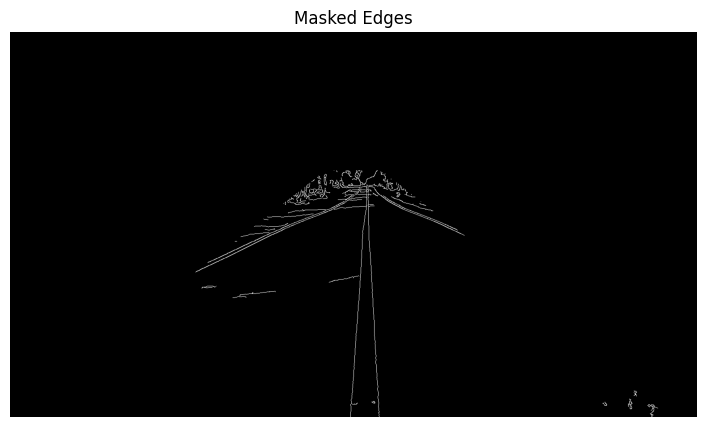

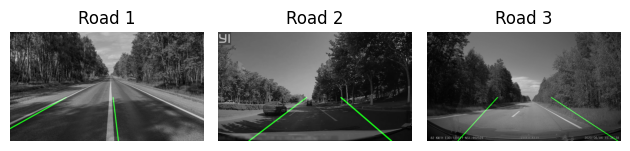

In [ ]:
r1BGR= cv2.cvtColor(r1, cv2.COLOR_GRAY2BGR)
r2BGR= cv2.cvtColor(r2, cv2.COLOR_GRAY2BGR)
r3BGR= cv2.cvtColor(r3, cv2.COLOR_GRAY2BGR)


road_images = [r1BGR, r2BGR, r3BGR]
titles = ["Road 1", "Road 2", "Road 3"]

plt.figure(figsize=(15, 5))

for i, img in enumerate(road_images):

    result = detect_lanes(
        img,
        show_mask=(i == 0)
    )

    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()